## Spherical Harmonics Fitting – Ideal Case and Damping Tests

This notebook evaluates the performance of spherical harmonics fitting using data sampled on a spherical shell, representing an ideal scenario for the method.

In the second part, different damping values are tested to assess their impact on the stability and accuracy of the inversion.

In [1]:
import numpy as np
import pandas as pd
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import glob
from stl import mesh
import os
from matplotlib.colors import LogNorm


import sys
sys.path.append("..")

import multipoles as mt
import micromag as mg
from micromag import MICROMETER_TO_METER, TESLA_TO_NANOTESLA

In [2]:
dir_micromagnetic_moments = pathlib.Path("../../data/micromag_models/real_micromagnetic_moments")
dir_spheric_shells = pathlib.Path("../..") / "data/micromag_models/spheric_shells"
stl_dir = pathlib.Path("../..") / "data/micromag_models/STL_ellipsoids"

In [3]:
micromag_moments = pd.read_csv(dir_micromagnetic_moments/"dipole_moments.csv")
micromag_moments.sort_values("name").reset_index(drop=True)
micromag_moments.head(5)

,name,mx,my,mz
0,eps0,1.727572e-17,1.727715e-17,1.687913e-17
1,eps10,-1.019756e-17,-1.018420e-17,3.515287e-20
2,eps11,-8.737511e-17,-8.727129e-17,-7.624085e-21
3,eps12,2.544569e-18,-4.704806e-19,4.893038e-17
4,eps13,-1.846870e-17,-2.001104e-18,-1.251612e-16


In [4]:
csv_names = sorted(glob.glob(f"{dir_spheric_shells}/*.csv"))
stl_names = sorted(glob.glob(f"{stl_dir}/*.stl"))

results = []
for i, (csv_file, stl_file) in enumerate(zip(csv_names, stl_names)):

    particle_name = str(os.path.splitext(os.path.basename(csv_file))[0])
    
    # === 1. Load CSV data ===
    df = pd.read_csv(csv_file)
    x = df["x"].values 
    y = df["y"].values 
    z = df["z"].values 
    bz = df["bz"].values 

    coordinates = (x, y, z)

    # Use location from the STL file
    m = mesh.Mesh.from_file(str(stl_file))
    location = np.array([np.mean(m.x),np.mean(m.y),np.mean(m.z)])

    sph = mt.SphericalHarmonicsBz(location, min_degree=1, max_degree=10).fit(coordinates, bz)
    # sph.update_location(coordinates, df)

    mx, my, mz = sph.magnetic_moment_

    results.append({
        "name": particle_name,
        "mx": mx,
        "my": my,
        "mz": mz,
    })


In [5]:
df_sh = pd.DataFrame(results)
df_sh.sort_values("name").reset_index(drop=True)
df_sh.head(5)

,name,mx,my,mz
0,eps0,1.727772e-17,1.727709e-17,1.688863e-17
1,eps1,5.333567e-17,-5.477363e-17,5.486512e-17
2,eps10,-1.019654e-17,-1.018278e-17,3.483632e-20
3,eps11,-8.735626e-17,-8.725208e-17,-6.807641e-21
4,eps12,2.544465e-18,-4.711139e-19,5.004306e-17


In [6]:
df_merged = micromag_moments.merge(
    df_sh,
    on="name",
    suffixes=("", "_sph")
)

df_merged.head()

,name,mx,my,mz,mx_sph,my_sph,mz_sph
0,eps0,1.727572e-17,1.727715e-17,1.687913e-17,1.727772e-17,1.727709e-17,1.688863e-17
1,eps10,-1.019756e-17,-1.018420e-17,3.515287e-20,-1.019654e-17,-1.018278e-17,3.483632e-20
2,eps11,-8.737511e-17,-8.727129e-17,-7.624085e-21,-8.735626e-17,-8.725208e-17,-6.807641e-21
3,eps12,2.544569e-18,-4.704806e-19,4.893038e-17,2.544465e-18,-4.711139e-19,5.004306e-17
4,eps13,-1.846870e-17,-2.001104e-18,-1.251612e-16,-1.846294e-17,-2.000448e-18,-1.211567e-16


In [7]:
def angular_distance(vec_a, vec_b):
    dot_product = np.dot(vec_a, vec_b)
    
    magnitude_a = np.linalg.norm(vec_a)
    magnitude_b = np.linalg.norm(vec_b)
    
    cos_theta = dot_product / (magnitude_a * magnitude_b)

    theta = np.rad2deg(np.arccos(cos_theta))
    
    return theta

In [8]:
angle_misfits = []
moment_misfits = []

for _, row in df_merged.iterrows():
    
    micromag_moment = row[["mx", "my", "mz"]].values
    spherical_moment = row[["mx_sph", "my_sph", "mz_sph"]].values

    amp = mg.vector_to_angles(micromag_moment)[2]
    eamp = mg.vector_to_angles(spherical_moment)[2]

    angle_misfit = angular_distance(micromag_moment, spherical_moment)
    m_misfit = abs((amp - eamp) / amp * 100)

    angle_misfits.append(angle_misfit)
    moment_misfits.append(m_misfit)

df_merged["angle_misfit"] = angle_misfits
df_merged["moment_misfit"] = moment_misfits

In [9]:
df_merged.head(10)

,name,mx,my,mz,mx_sph,my_sph,mz_sph,angle_misfit,moment_misfit
0,eps0,1.727572e-17,1.727715e-17,1.687913e-17,1.727772e-17,1.727709e-17,1.688863e-17,0.013846,0.021990
1,eps10,-1.019756e-17,-1.018420e-17,3.515287e-20,-1.019654e-17,-1.018278e-17,3.483632e-20,0.001673,0.011945
2,eps11,-8.737511e-17,-8.727129e-17,-7.624085e-21,-8.735626e-17,-8.725208e-17,-6.807641e-21,0.000400,0.021792
3,eps12,2.544569e-18,-4.704806e-19,4.893038e-17,2.544465e-18,-4.711139e-19,5.004306e-17,0.067178,2.267729
4,eps13,-1.846870e-17,-2.001104e-18,-1.251612e-16,-1.846294e-17,-2.000448e-18,-1.211567e-16,0.272143,3.130100
5,eps14,1.723777e-17,-7.829008e-17,3.575992e-16,1.723124e-17,-7.827996e-17,3.503259e-16,0.251902,1.936334
6,eps15,1.825247e-17,1.819238e-17,1.819005e-17,1.826332e-17,1.818643e-17,1.815397e-17,0.061144,0.056875
7,eps16,-4.810644e-17,4.881597e-17,-4.907527e-17,-4.813911e-17,4.880852e-17,-4.901582e-17,0.044303,0.024032
8,eps17,-2.985054e-16,-2.993368e-16,2.989325e-16,-2.986089e-16,-2.994930e-16,2.971002e-16,0.177642,0.174875
9,eps18,5.034172e-16,5.033993e-16,5.018909e-16,5.035158e-16,5.036931e-16,4.978081e-16,0.230751,0.243223


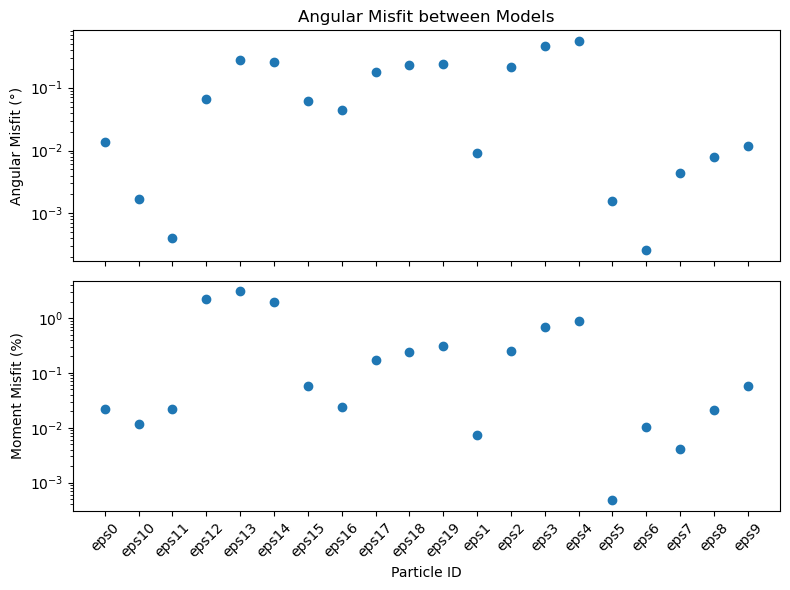

In [10]:
x = df_merged["name"]

fig, axes = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

# Angular misfit
axes[0].scatter(x, df_merged["angle_misfit"])
axes[0].set_ylabel("Angular Misfit (°)")
axes[0].set_title("Angular Misfit between Models")
axes[0].set_yscale("log")

# Moment misfit
axes[1].scatter(x, df_merged["moment_misfit"])
axes[1].set_ylabel("Moment Misfit (%)")
axes[1].set_xlabel("Particle ID")
axes[1].set_yscale("log")
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

## Tests with different damping values

In [11]:
results_damping = []
dampings = [1e-3, 1e-2, 1e-1, 1e0, 1e1, 1e2, 1e3]

for damping in dampings:
    for i, (csv_file, stl_file) in enumerate(zip(csv_names, stl_names)):

        particle_name = str(os.path.splitext(os.path.basename(csv_file))[0])
        
        df = pd.read_csv(csv_file)
        x, y, z, bz = df["x"].values, df["y"].values, df["z"].values, df["bz"].values
        coordinates = (x, y, z)

        m = mesh.Mesh.from_file(str(stl_file))
        location = np.array([np.mean(m.x), np.mean(m.y), np.mean(m.z)])

        sph = mt.SphericalHarmonicsBz(
            location,
            damping=damping,
            min_degree=1,
            max_degree=10
        ).fit(coordinates, bz)

        mx, my, mz = sph.magnetic_moment_

        results_damping.append({
            "name": particle_name,
            "damping": damping, 
            "mx": mx,
            "my": my,
            "mz": mz,
        })

In [12]:
df_sh_dampings = pd.DataFrame(results_damping)
df_sh_dampings.sort_values("name").reset_index(drop=True)
df_sh_dampings.head(5)

,name,damping,mx,my,mz
0,eps0,0.001,1.727791e-17,1.727728e-17,1.688884e-17
1,eps1,0.001,5.333622e-17,-5.477419e-17,5.486589e-17
2,eps10,0.001,-1.019666e-17,-1.018291e-17,3.483700e-20
3,eps11,0.001,-8.735734e-17,-8.725315e-17,-6.807808e-21
4,eps12,0.001,2.544495e-18,-4.711207e-19,5.004162e-17


In [13]:
df_all = micromag_moments.merge(
    df_sh_dampings,
    on="name",
    suffixes=("", "_sph")
)

In [14]:
df_all.head(-10)

,name,mx,my,mz,damping,mx_sph,my_sph,mz_sph
0,eps0,1.727572e-17,1.727715e-17,1.687913e-17,0.001,1.727791e-17,1.727728e-17,1.688884e-17
1,eps0,1.727572e-17,1.727715e-17,1.687913e-17,0.010,1.727789e-17,1.727726e-17,1.688882e-17
2,eps0,1.727572e-17,1.727715e-17,1.687913e-17,0.100,1.727772e-17,1.727709e-17,1.688863e-17
3,eps0,1.727572e-17,1.727715e-17,1.687913e-17,1.000,1.727603e-17,1.727542e-17,1.688671e-17
4,eps0,1.727572e-17,1.727715e-17,1.687913e-17,10.000,1.725910e-17,1.725868e-17,1.686762e-17
...,...,...,...,...,...,...,...,...
125,eps7,4.638268e-16,7.229933e-17,1.874169e-18,1000.000,4.129103e-16,6.601751e-17,2.121452e-18
126,eps8,-6.675010e-16,1.121547e-16,2.659973e-18,0.001,-6.673534e-16,1.122131e-16,2.619470e-18
127,eps8,-6.675010e-16,1.121547e-16,2.659973e-18,0.010,-6.673526e-16,1.122130e-16,2.619476e-18
128,eps8,-6.675010e-16,1.121547e-16,2.659973e-18,0.100,-6.673449e-16,1.122121e-16,2.619538e-18


In [15]:
angle_misfits = []
moment_misfits = []

for _, row in df_all.iterrows():
    
    micromag_moment = row[["mx", "my", "mz"]].values
    spherical_moment = row[["mx_sph", "my_sph", "mz_sph"]].values

    amp = mg.vector_to_angles(micromag_moment)[2]
    eamp = mg.vector_to_angles(spherical_moment)[2]

    angle_misfit = angular_distance(micromag_moment, spherical_moment)
    m_misfit = abs((amp - eamp) / amp * 100)

    angle_misfits.append(angle_misfit)
    moment_misfits.append(m_misfit)

df_all["angle_misfit"] = angle_misfits
df_all["moment_misfit"] = moment_misfits

In [16]:
df_all.head(5)

,name,mx,my,mz,damping,mx_sph,my_sph,mz_sph,angle_misfit,moment_misfit
0,eps0,1.727572e-17,1.727715e-17,1.687913e-17,0.001,1.727791e-17,1.727728e-17,1.688884e-17,0.013892,0.023119
1,eps0,1.727572e-17,1.727715e-17,1.687913e-17,0.010,1.727789e-17,1.727726e-17,1.688882e-17,0.013888,0.023016
2,eps0,1.727572e-17,1.727715e-17,1.687913e-17,0.100,1.727772e-17,1.727709e-17,1.688863e-17,0.013846,0.021990
3,eps0,1.727572e-17,1.727715e-17,1.687913e-17,1.000,1.727603e-17,1.727542e-17,1.688671e-17,0.013429,0.011726
4,eps0,1.727572e-17,1.727715e-17,1.687913e-17,10.000,1.725910e-17,1.725868e-17,1.686762e-17,0.009287,0.090781


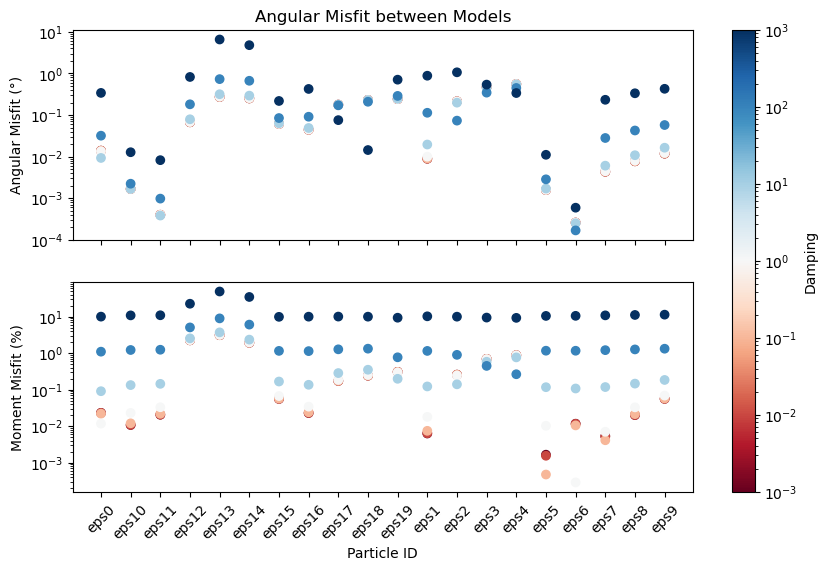

In [17]:
norm = LogNorm(vmin=df_all["damping"].min(), vmax=df_all["damping"].max())

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

x = df_all["name"]
c = df_all["damping"]

# Angular misfit
sc1 = axes[0].scatter(x, df_all["angle_misfit"], c=c, cmap="RdBu", norm=norm)
axes[0].set_ylabel("Angular Misfit (°)")
axes[0].set_title("Angular Misfit between Models")
axes[0].set_yscale("log")

# Moment misfit
sc2 = axes[1].scatter(x, df_all["moment_misfit"], c=c, cmap="RdBu", norm=norm)

axes[1].set_ylabel("Moment Misfit (%)")
axes[1].set_xlabel("Particle ID")
axes[1].set_yscale("log")
axes[1].tick_params(axis='x', rotation=45)


# colorbar (compartilhada)
cbar = fig.colorbar(sc2, ax=axes, orientation="vertical")
cbar.set_label("Damping")

plt.show()